In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
netflix = pd.read_csv('netflix_titles.csv')


In [4]:
netflix.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [5]:
netflix.shape

(8807, 12)

In [6]:
netflix.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [7]:
netflix.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [8]:
netflix['director'] = netflix['director'].fillna('Unknown')

netflix['cast'] = netflix['cast'].fillna('Unknown')

In [9]:
netflix['country'] = netflix['country'].fillna('Unknown')

In [10]:
netflix.isnull().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           4
duration         3
listed_in        0
description      0
dtype: int64

In [11]:
netflix['date_added'] = netflix['date_added'].str.strip()

In [12]:
netflix['date_added'] = pd.to_datetime(
    netflix['date_added'],
    errors='coerce'
)

In [13]:
netflix['date_added'].head()

0   2021-09-25
1   2021-09-24
2   2021-09-24
3   2021-09-24
4   2021-09-24
Name: date_added, dtype: datetime64[us]

In [14]:
netflix['is_movie'] = (
    netflix['type'] == 'Movie'
).astype(int)

In [15]:
netflix['content_type'] = netflix['type']

In [16]:
netflix['year_added'] = netflix['date_added'].dt.year

In [17]:
netflix['month_added'] = netflix['date_added'].dt.month_name()


Pie chart

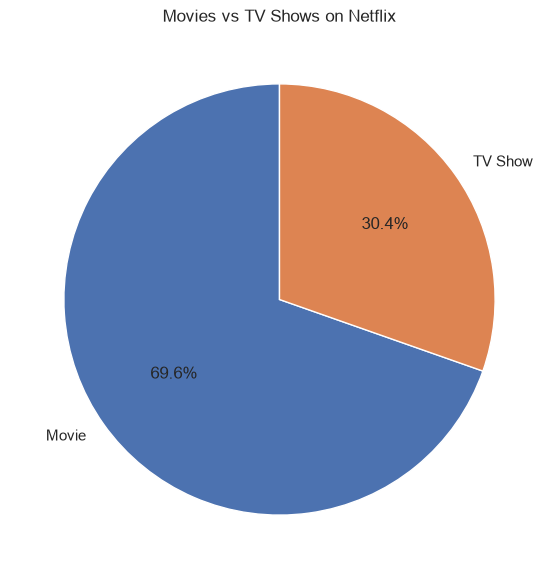

In [18]:
type_counts = netflix['type'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    type_counts,
    labels=type_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Movies vs TV Shows on Netflix')

plt.show()

In [19]:
year_counts = (
    netflix['release_year']
    .value_counts()
    .sort_index()
)

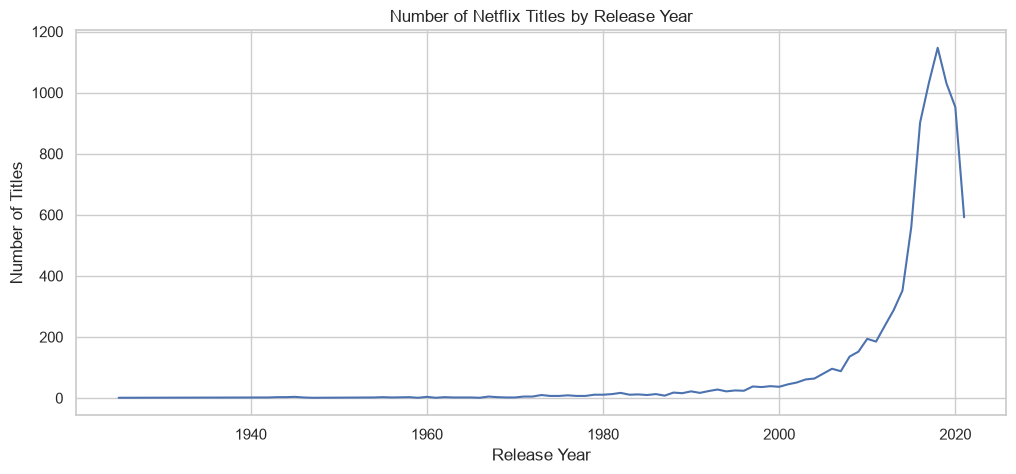

In [20]:
plt.figure(figsize=(12,5))

plt.plot(
    year_counts.index,
    year_counts.values
)

plt.title('Number of Netflix Titles by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.show()

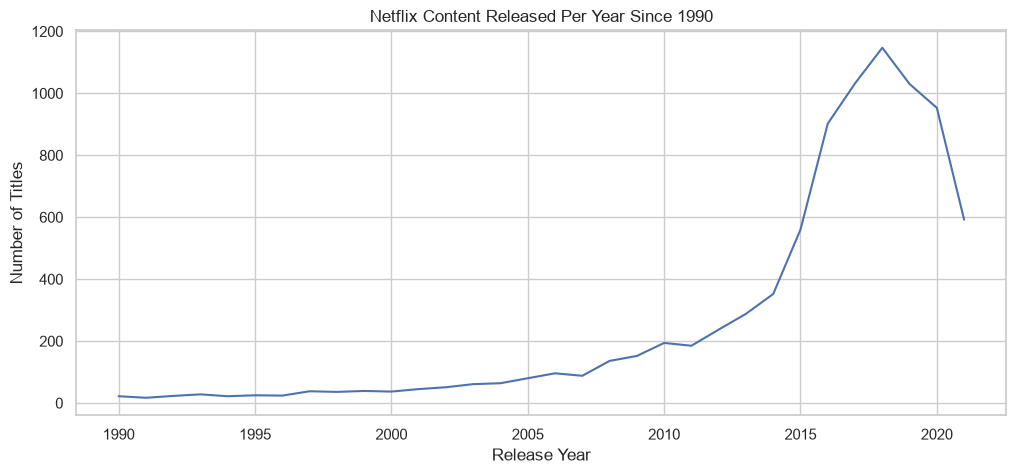

In [21]:
recent = netflix[
    netflix['release_year'] >= 1990
]

year_counts = (
    recent['release_year']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12,5))

plt.plot(
    year_counts.index,
    year_counts.values
)

plt.title('Netflix Content Released Per Year Since 1990')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.show()

In [22]:
genres = (
    netflix['listed_in']
    .str.split(',')
    .explode()
    .str.strip()
)

In [23]:
top_genres = genres.value_counts().head(10)

top_genres

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

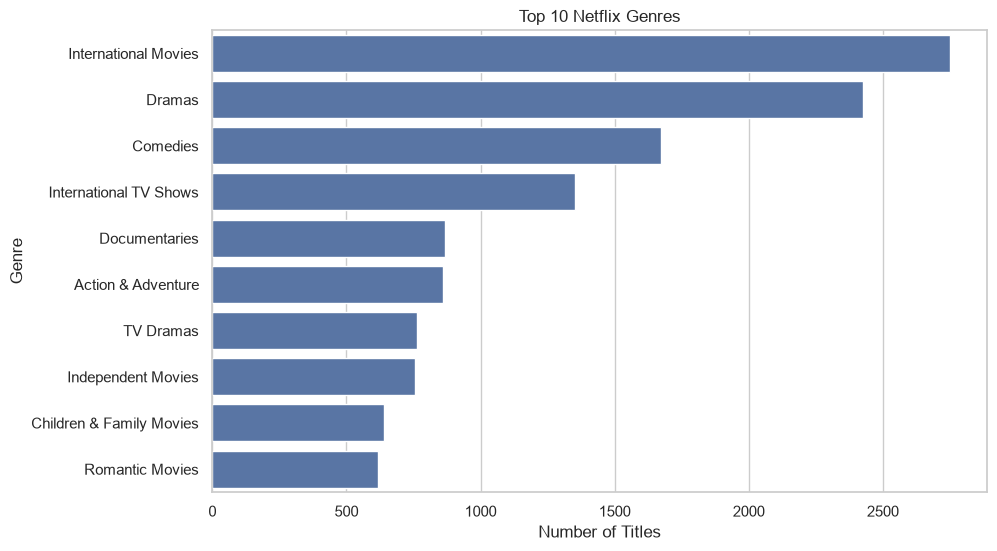

In [24]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title('Top 10 Netflix Genres')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')

plt.show()

In [27]:
countries = (
    netflix['country']
    .str.split(',')
    .explode()
    .str.strip()
)

In [28]:
top_countries = countries.value_counts().head(5)

top_countries

country
United States     3690
India             1046
Unknown            831
United Kingdom     806
Canada             445
Name: count, dtype: int64

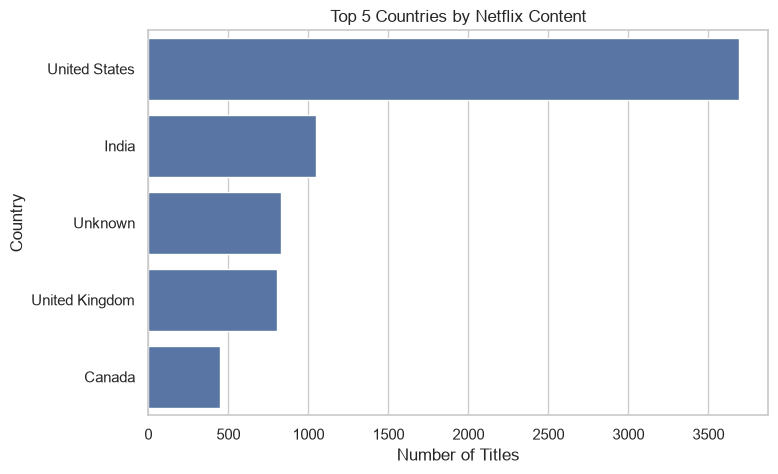

In [29]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title('Top 5 Countries by Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')

plt.show()

In [30]:
top5 = top_countries.index.tolist()

In [31]:
country_df = netflix.copy()

country_df['country'] = (
    country_df['country']
    .str.split(',')
)

country_df = country_df.explode('country')

country_df['country'] = (
    country_df['country']
    .str.strip()
)

In [32]:
country_df = country_df[
    country_df['country'].isin(top5)
]

In [33]:
country_type = pd.crosstab(
    country_df['country'],
    country_df['type']
)

country_type

ValueError: cannot reindex on an axis with duplicate labels

In [34]:
plt.figure(figsize=(8,5))

sns.heatmap(
    country_type,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Netflix Content by Country and Type')

plt.show()

NameError: name 'country_type' is not defined

<Figure size 800x500 with 0 Axes>

In [35]:
countries = (
    netflix['country']
    .str.split(',')
    .explode()
    .str.strip()
)

In [36]:
top_countries = countries.value_counts().head(5)

top_countries

country
United States     3690
India             1046
Unknown            831
United Kingdom     806
Canada             445
Name: count, dtype: int64

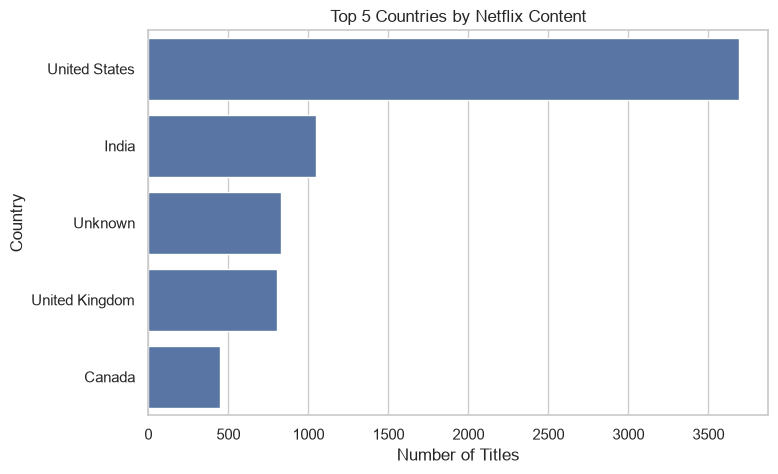

In [37]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title('Top 5 Countries by Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')

plt.show()

In [38]:
top5 = top_countries.index.tolist()

In [39]:
country_df = netflix.copy()

country_df['country'] = (
    country_df['country']
    .str.split(',')
)

country_df = country_df.explode('country')

country_df['country'] = (
    country_df['country']
    .str.strip()
)

In [40]:
country_df = country_df[
    country_df['country'].isin(top5)
]

In [41]:
country_type = pd.crosstab(
    country_df['country'],
    country_df['type']
)

country_type

ValueError: cannot reindex on an axis with duplicate labels

In [42]:
decade_counts = (
    netflix['release_decade']
    .value_counts()
    .sort_index()
)

KeyError: 'release_decade'

Predict after 2 years

In [43]:
yearly = (
    netflix.groupby('release_year')
    .size()
    .reset_index(name='content_count')
)

In [44]:
yearly_recent = yearly[
    yearly['release_year'] >= 2000
]

In [45]:
from sklearn.linear_model import LinearRegression

ModuleNotFoundError: No module named 'sklearn'

In [46]:
pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 2.2 MB/s eta 0:00:04
   ----- ---------------------------------- 1.0/8.4 MB 2.5 MB/s eta 0:00:03
   ------- -------------------------------- 1.6/8.4 MB 2.4 MB/s eta 0:00:03
   ---------- ----------------------------- 2.1/8.4 MB 2.4 MB/s eta 0:00:03
   ------------ --------------------------- 2.6/8.4 MB 2.6 MB/s eta 0:00:03
   --------------- ------------------------ 3.1/8.4 MB 2.6 MB/s eta 0:00:03
   ----------------- ---------------------- 3.7/8.4 MB 2.6 MB/s eta 0:00:02
   --------------------- ------------------ 4.5/8.4 MB 2.6 MB/s eta 0:00:02
   ---------------------- ----------------- 4.7/8.4 MB 2.6 MB/s eta 0:00:02
   ----------------------- ---------------- 5.0/8.4 MB 2.5 MB/s eta 0:00:02
   -------------------------- ------------- 5.5/8.4 MB 2.4 MB/s eta 0:00:02
   ---------------------------- ----------- 6.0/8.4 MB 2.4 MB/s eta 0:00:01
   ----------------

In [47]:
from sklearn.linear_model import LinearRegression

In [48]:
X = yearly_recent[['release_year']]
y = yearly_recent['content_count']

In [49]:
model = LinearRegression()

model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[51.1]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['release_year']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.024e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [50]:
last_year = yearly_recent['release_year'].max()

last_year

np.int64(2021)

In [51]:
future_years = pd.DataFrame({
    'release_year': [
        last_year + 1,
        last_year + 2
    ]
})

future_predictions = model.predict(future_years)

future_years['Predicted_Content'] = future_predictions

future_years

,release_year,Predicted_Content
0,2022,964.090909
1,2023,1015.189723
